# Melanoma classification

The objective is to classify dermoscopy images of skin lesions as **melanoma** or **benign**. The data comes from the [HAM10000](https://doi.org/10.1038/sdata.2018.161) dataset (via the Hugging Face mirror `marmal88/skin_cancer`), which labels each image with one of seven diagnoses. All non-melanoma diagnoses are grouped into a single benign class.

Two models are compared:

1. **Small CNN from scratch**: a simple convolutional network trained only on this data.
2. **Transfer learning**: a ResNet-18 pretrained on ImageNet, fine-tuned on this data.

In [1]:
%pip install torch torchvision datasets matplotlib seaborn scikit-learn ipywidgets --quiet

Note: you may need to restart the kernel to use updated packages.


## Dependencies

In [2]:
import numpy as np
import torch
import torchvision
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve

### Configuration

- **IMG_SIZE**: Images are resized to 224×224, the input size ResNet-18 was pretrained on.
- **device**: Uses a CUDA GPU or Apple Silicon (MPS) if available, otherwise CPU.

In [3]:
IMG_SIZE   = 224
BATCH_SIZE = 32
EPOCHS     = 5

torch.manual_seed(42)
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: mps


## Load the dataset

The dataset is downloaded from the Hugging Face Hub (~3.5 GB) and cached locally. It comes pre-split into train, validation and test sets. The `dx` column holds one of seven diagnoses:

| `dx` | Description |
|---|---|
| `melanoma` | Malignant melanoma |
| `melanocytic_Nevi` | Common mole |
| `benign_keratosis-like_lesions` | Seborrheic keratosis, solar lentigo, lichen planus-like keratosis |
| `basal_cell_carcinoma` | Basal cell carcinoma |
| `actinic_keratoses` | Actinic keratosis / intraepithelial carcinoma |
| `vascular_lesions` | Angiomas, angiokeratomas, hemorrhages |
| `dermatofibroma` | Dermatofibroma |

In [4]:
dataset = load_dataset('marmal88/skin_cancer', cache_dir='../data')
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'image_id', 'lesion_id', 'dx', 'dx_type', 'age', 'sex', 'localization'],
        num_rows: 9577
    })
    validation: Dataset({
        features: ['image', 'image_id', 'lesion_id', 'dx', 'dx_type', 'age', 'sex', 'localization'],
        num_rows: 2492
    })
    test: Dataset({
        features: ['image', 'image_id', 'lesion_id', 'dx', 'dx_type', 'age', 'sex', 'localization'],
        num_rows: 1285
    })
})

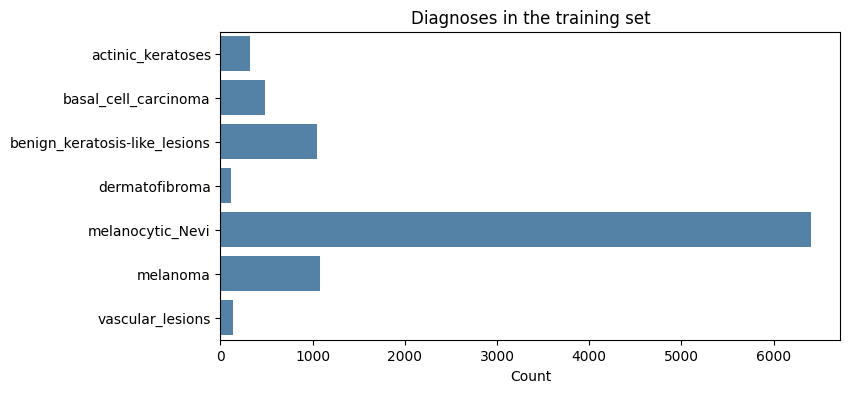

In [5]:
train_dx = np.array(dataset['train']['dx'])
labels, counts = np.unique(train_dx, return_counts=True)

plt.figure(figsize=(8, 4))
sns.barplot(x=counts, y=labels, color='steelblue')
plt.title('Diagnoses in the training set')
plt.xlabel('Count')
plt.show()

### Binary labels

Melanoma is labeled `1` and everything else `0`. The classes are heavily imbalanced (roughly 1 melanoma for every 8 benign lesions), so a model that always predicts benign would already score ~89% accuracy. Because of this, **ROC AUC** and melanoma **recall** are more informative than accuracy.

In [6]:
n_mel = (train_dx == 'melanoma').sum()
n_ben = (train_dx != 'melanoma').sum()
print(f"Melanoma: {n_mel}  Benign: {n_ben}  Ratio: 1:{n_ben / n_mel:.1f}")

Melanoma: 1076  Benign: 8501  Ratio: 1:7.9


### Transforms

- **Resize**: Scales every image to 224×224.
- **RandomHorizontalFlip / RandomVerticalFlip / RandomRotation**: Lesions have no natural orientation, so flips and rotations are cheap, label-preserving augmentation (training only).
- **ColorJitter**: Small brightness/contrast changes to simulate differences in lighting and cameras (training only).
- **Normalize**: Uses the ImageNet mean and standard deviation, which the pretrained ResNet expects.

In [7]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize((IMG_SIZE, IMG_SIZE)),
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.RandomVerticalFlip(),
    torchvision.transforms.RandomRotation(20),
    torchvision.transforms.ColorJitter(brightness=0.1, contrast=0.1),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean, std),
])

eval_transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize((IMG_SIZE, IMG_SIZE)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean, std),
])

def make_transform(transform):
    def apply(batch):
        return {
            'image': [transform(img.convert('RGB')) for img in batch['image']],
            'label': [float(dx == 'melanoma') for dx in batch['dx']],
        }
    return apply

def collate(batch):
    images = torch.stack([b['image'] for b in batch])
    labels = torch.tensor([b['label'] for b in batch])
    return images, labels

train_ds = dataset['train'].with_transform(make_transform(train_transform))
val_ds   = dataset['validation'].with_transform(make_transform(eval_transform))
test_ds  = dataset['test'].with_transform(make_transform(eval_transform))

train_loader = torch.utils.data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader   = torch.utils.data.DataLoader(val_ds, batch_size=BATCH_SIZE, collate_fn=collate)
test_loader  = torch.utils.data.DataLoader(test_ds, batch_size=BATCH_SIZE, collate_fn=collate)

print(f"Train: {len(train_ds)}  Validation: {len(val_ds)}  Test: {len(test_ds)}")

Train: 9577  Validation: 2492  Test: 1285


### Visualize samples

Display a random 3×3 grid of training images with their binary label.

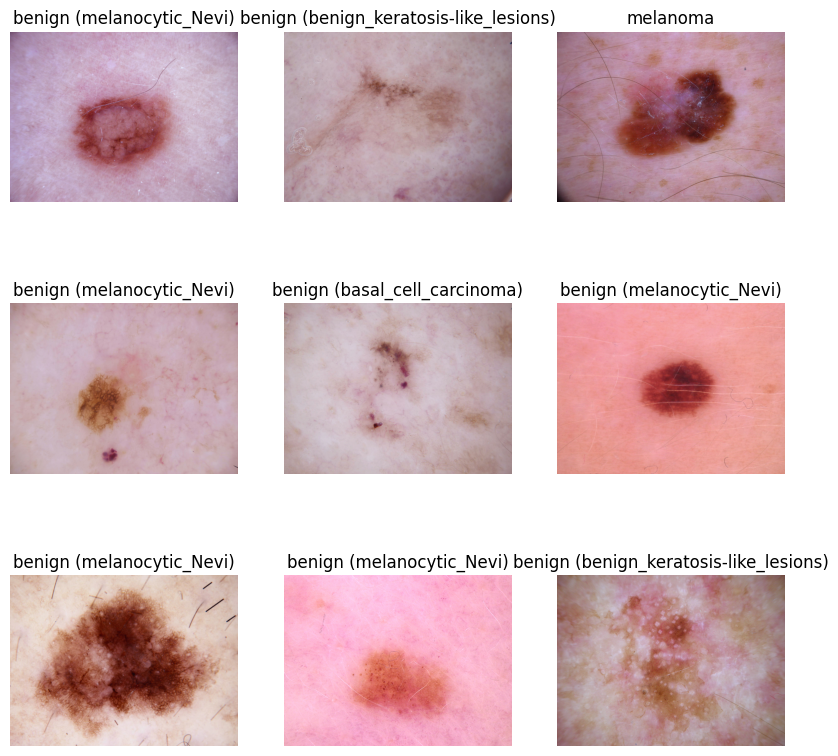

In [8]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))
for ax in axes.flatten():
    idx = torch.randint(len(dataset['train']), size=(1,)).item()
    sample = dataset['train'][idx]
    ax.set_title('melanoma' if sample['dx'] == 'melanoma' else f"benign ({sample['dx']})")
    ax.axis('off')
    ax.imshow(sample['image'])
plt.show()

## Training utilities

Both models output a single logit and share the same training loop.

- **BCEWithLogitsLoss**: Binary cross-entropy applied to the raw logit (more numerically stable than a sigmoid followed by BCE).
- **pos_weight**: Weights melanoma errors by the benign:melanoma ratio, so the model can't minimize loss by ignoring the rare class.
- **Adam**: Adaptive optimizer.
- The checkpoint with the best **validation AUC** is kept.

In [9]:
pos_weight = torch.tensor([n_ben / n_mel], dtype=torch.float32, device=device)
criterion  = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)

def predict(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(device)).squeeze(1)
            probs.append(torch.sigmoid(logits).cpu())
            targets.append(labels)
    return torch.cat(probs).numpy(), torch.cat(targets).numpy()

def train(model, optimizer, epochs=EPOCHS):
    model.to(device)
    history = {'train_loss': [], 'val_auc': []}
    best_auc, best_state = 0, None

    for epoch in range(epochs):
        model.train()
        running_loss = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images).squeeze(1), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        train_loss = running_loss / len(train_ds)
        val_probs, val_targets = predict(model, val_loader)
        val_auc = roc_auc_score(val_targets, val_probs)
        history['train_loss'].append(train_loss)
        history['val_auc'].append(val_auc)
        print(f"Epoch {epoch + 1}/{epochs}  loss: {train_loss:.4f}  val AUC: {val_auc:.4f}")

        if val_auc > best_auc:
            best_auc   = val_auc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return history

## Model 1: Small CNN from scratch

Four convolutional blocks, each doubling the number of filters and halving the spatial size.

- **Conv2d (3×3)**: Learns local patterns such as edges, colors and textures.
- **BatchNorm2d**: Normalizes activations, which stabilizes and speeds up training.
- **MaxPool2d (2×2)**: Downsamples 224 → 112 → 56 → 28 → 14.
- **AdaptiveAvgPool2d**: Averages each feature map to a single value, giving a 256-dimensional vector regardless of input size.
- **Dropout(0.3)** and **Linear (256 → 1)**: Regularized classification head producing one logit.

In [10]:
class SmallCNN(torch.nn.Module):
    def __init__(self):
        super(SmallCNN, self).__init__()

        def block(in_ch, out_ch):
            return torch.nn.Sequential(
                torch.nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                torch.nn.BatchNorm2d(out_ch),
                torch.nn.ReLU(),
                torch.nn.MaxPool2d(2),
            )

        self.features = torch.nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.pool     = torch.nn.AdaptiveAvgPool2d(1)
        self.dropout  = torch.nn.Dropout(0.3)
        self.fc       = torch.nn.Linear(256, 1)

    def forward(self, x):
        x = self.pool(self.features(x)).flatten(1)
        return self.fc(self.dropout(x))

cnn = SmallCNN()
print(f"Parameters: {sum(p.numel() for p in cnn.parameters()):,}")

Parameters: 389,633


In [11]:
cnn_history = train(cnn, torch.optim.Adam(cnn.parameters(), lr=1e-3))

Epoch 1/5  loss: 0.9952  val AUC: 0.7994
Epoch 2/5  loss: 0.9376  val AUC: 0.8353
Epoch 3/5  loss: 0.8869  val AUC: 0.8544
Epoch 4/5  loss: 0.8647  val AUC: 0.8570
Epoch 5/5  loss: 0.8436  val AUC: 0.8619


## Model 2: Transfer learning with ResNet-18

ResNet-18 was pretrained on ImageNet's 1.2M images, so its early layers already detect generic features (edges, textures, shapes). Only the final fully connected layer is replaced (512 → 1) and the whole network is fine-tuned with a small learning rate so the pretrained weights aren't destroyed.

In [12]:
resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
resnet.fc = torch.nn.Linear(resnet.fc.in_features, 1)
print(f"Parameters: {sum(p.numel() for p in resnet.parameters()):,}")

Parameters: 11,177,025


In [13]:
resnet_history = train(resnet, torch.optim.Adam(resnet.parameters(), lr=1e-4))

Epoch 1/5  loss: 0.8141  val AUC: 0.9028
Epoch 2/5  loss: 0.7037  val AUC: 0.9220
Epoch 3/5  loss: 0.6296  val AUC: 0.9311
Epoch 4/5  loss: 0.5977  val AUC: 0.9261
Epoch 5/5  loss: 0.5889  val AUC: 0.9408


## Evaluation

### Training curves

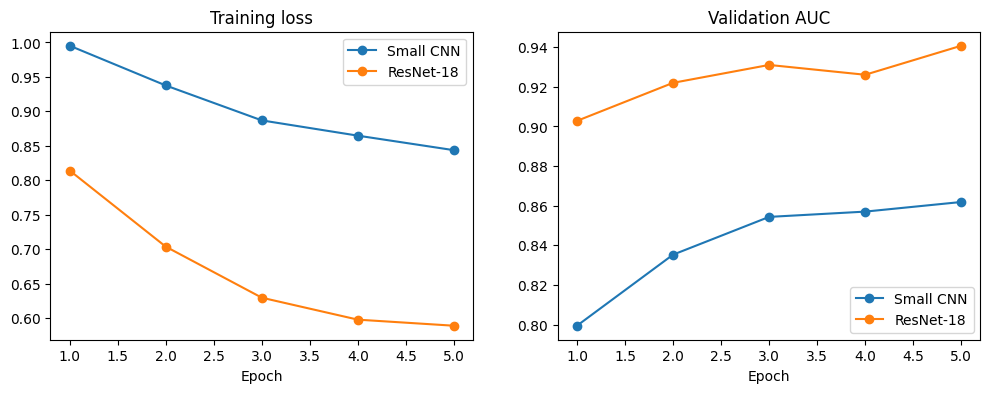

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in [('Small CNN', cnn_history), ('ResNet-18', resnet_history)]:
    epochs = range(1, len(history['train_loss']) + 1)
    axes[0].plot(epochs, history['train_loss'], marker='o', label=name)
    axes[1].plot(epochs, history['val_auc'], marker='o', label=name)
axes[0].set_title('Training loss')
axes[1].set_title('Validation AUC')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
plt.show()

### Test set results

Predictions use a 0.5 probability threshold. In a screening setting the threshold would typically be lowered to trade more false alarms for fewer missed melanomas.

In [15]:
results = {}
for name, model in [('Small CNN', cnn), ('ResNet-18', resnet)]:
    probs, targets = predict(model, test_loader)
    results[name] = (probs, targets)
    print(f"=== {name} ===  AUC: {roc_auc_score(targets, probs):.4f}")
    print(classification_report(targets, probs > 0.5, target_names=['benign', 'melanoma'], digits=3))

=== Small CNN ===  AUC: 0.8630
              precision    recall  f1-score   support

      benign      0.978     0.661     0.789      1141
    melanoma      0.247     0.882     0.386       144

    accuracy                          0.686      1285
   macro avg      0.613     0.771     0.587      1285
weighted avg      0.896     0.686     0.744      1285

=== ResNet-18 ===  AUC: 0.9434
              precision    recall  f1-score   support

      benign      0.985     0.838     0.905      1141
    melanoma      0.411     0.896     0.563       144

    accuracy                          0.844      1285
   macro avg      0.698     0.867     0.734      1285
weighted avg      0.920     0.844     0.867      1285



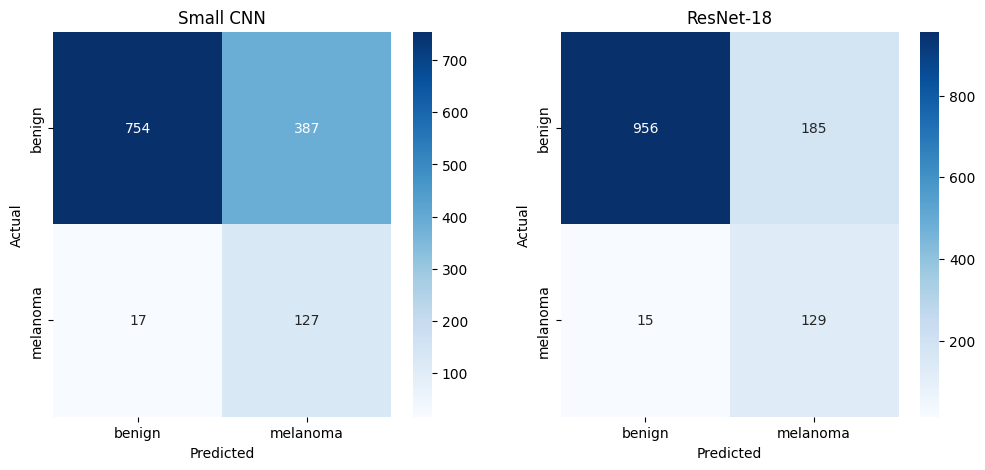

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, (probs, targets)) in zip(axes, results.items()):
    cm = confusion_matrix(targets, probs > 0.5)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['benign', 'melanoma'], yticklabels=['benign', 'melanoma'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.show()

### ROC curves

The ROC curve plots the true positive rate (melanomas caught) against the false positive rate (benign lesions flagged) across all thresholds. The area under the curve (AUC) summarizes this into one number: 0.5 is random guessing, 1.0 is perfect.

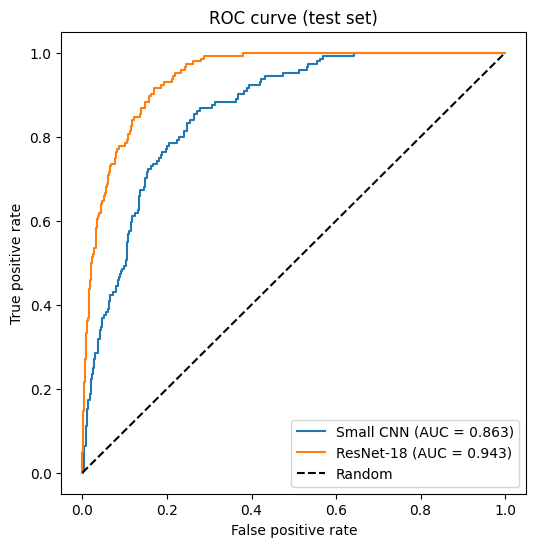

In [17]:
plt.figure(figsize=(6, 6))
for name, (probs, targets) in results.items():
    fpr, tpr, _ = roc_curve(targets, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(targets, probs):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve (test set)')
plt.legend()
plt.show()

## Conclusion

The pretrained ResNet-18 should outperform the small CNN on both AUC and melanoma recall, despite the same number of epochs. Features learned from ImageNet transfer well to dermoscopy images, while the small CNN has to learn everything from ~10k images.

Possible next steps:

- Train for more epochs with a learning rate scheduler.
- Tune the decision threshold on the validation set for a target sensitivity.
- Use a larger backbone (EfficientNet, ConvNeXt) or higher resolution.
- Group splits by `lesion_id`: HAM10000 contains several images of the same lesion, which can leak between splits and inflate scores.